In [8]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
train_dir = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/training/"
test_dir = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/test/"

In [10]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = dir.name   # 'day' atau 'night'
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

In [11]:
train_img = load_dataset(train_dir)
print(len(train_img))

240


In [12]:
train_img[0]

(array([[[124, 167, 210],
         [124, 167, 210],
         [124, 167, 210],
         ...,
         [120, 161, 205],
         [120, 161, 205],
         [118, 159, 203]],
 
        [[124, 167, 210],
         [124, 167, 210],
         [124, 167, 210],
         ...,
         [120, 161, 205],
         [120, 161, 205],
         [117, 158, 202]],
 
        [[124, 167, 210],
         [124, 167, 210],
         [124, 167, 210],
         ...,
         [120, 161, 205],
         [120, 161, 205],
         [117, 158, 202]],
 
        ...,
 
        [[102, 100,  88],
         [ 78,  76,  64],
         [ 67,  65,  53],
         ...,
         [113, 102,  98],
         [112, 101,  97],
         [113, 102,  98]],
 
        [[ 92,  90,  78],
         [ 63,  61,  49],
         [ 63,  61,  49],
         ...,
         [119, 105, 102],
         [119, 105, 102],
         [120, 106, 103]],
 
        [[ 97,  95,  83],
         [ 65,  63,  51],
         [ 56,  54,  42],
         ...,
         [119, 105, 102],
  

In [13]:
pick_random = np.random.randint(0, len(train_img))
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 67
(439, 640, 3)


In [14]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (458, 800, 3)
Label	: night


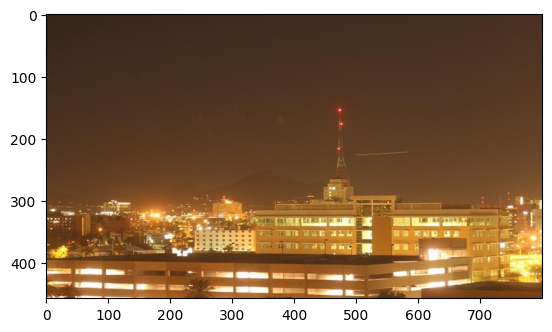

In [15]:
random_img_viz(train_img)

In [16]:
def standarized_input(image):
    # resize ke w: 1100, h: 600
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    # day = 1; night = 0
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [17]:
train_std_img_list = preprocess(train_img)

pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 133
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 1


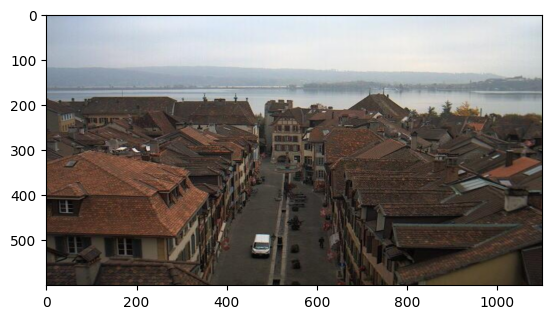

In [18]:
random_img_viz(train_std_img_list)

In [19]:
def standarized_input(image):
    # resize ke w: 1100, h: 600
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    # day = 1; night = 0
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [20]:
train_std_img_list = preprocess(train_img)

pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)   # harusnya (600, 1100, 3)

Image 91
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


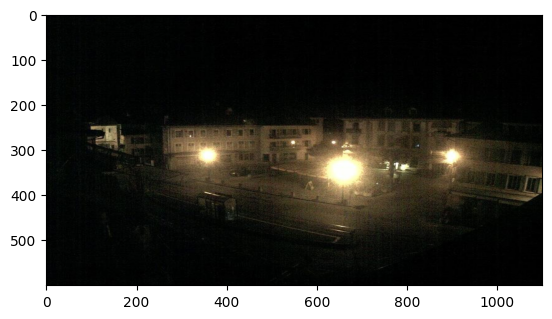

In [21]:
random_img_viz(train_std_img_list)

In [22]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(img_hsv[:, :, 2])   # channel V
    area = image.shape[0] * image.shape[1]
    return sum_brightness / area

Image 217
Avg Brightness: 93.7349


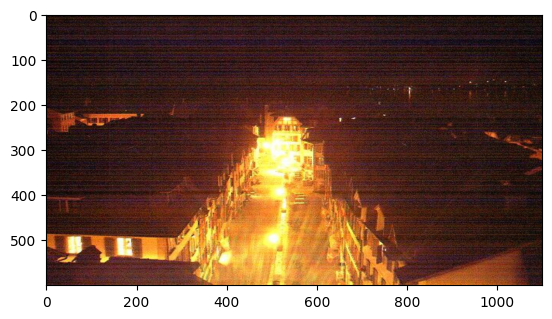

In [23]:
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

In [24]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    return 1 if avg > threshold else 0

Image 36
Actual label: 1
Predicted label: 1


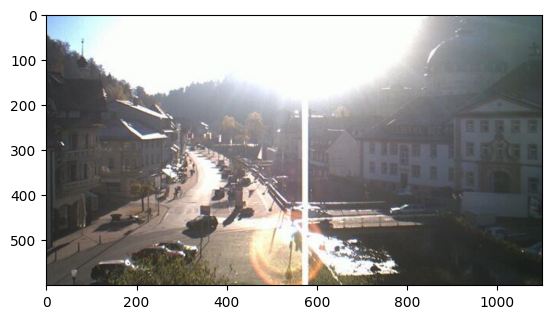

In [25]:
rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

In [26]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [27]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [28]:
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [29]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        avg_list.append(avg_brightness(img[0]))
        labels.append(img[1])

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,181.735806,1.0
1,136.946642,1.0
2,170.984826,1.0
3,165.241074,1.0
4,129.237782,1.0


In [30]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,123.281580,1.0
1,105.513033,1.0
2,191.237441,1.0
3,158.883767,1.0
4,129.938794,1.0


In [31]:
from sklearn.svm import SVC

X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [32]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


In [33]:
# SOAL 2

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import matplotlib.image as mpimg
import cv2
import numpy as np
import pandas as pd

train_dir = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/training/"
test_dir  = "/content/drive/MyDrive/Colab Notebooks/datasets/images/images/test/"

def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for d in sorted(p.iterdir()):
        if not d.is_dir():
            continue
        label = d.name
        for file in sorted(d.iterdir()):
            if file.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                img = mpimg.imread(file)
                if img is not None:
                    img_list.append((img, label))
    return img_list

def preprocess(img_list):
    out = []
    for img, label in img_list:
        std_img = cv2.resize(img, (1100, 600))
        out.append((std_img, 1 if label == 'day' else 0))
    return out

train_std_img_list = preprocess(load_dataset(train_dir))
test_std_img_list = preprocess(load_dataset(test_dir))
print("train:", len(train_std_img_list), "| test:", len(test_std_img_list))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train: 240 | test: 160
